# 03 · Incidents: Feature Engineering

**Feature engineering = turning raw columns into numbers and signals a model can learn from.**
A model can't understand "opened at 2016-03-14 09:37". It *can* learn from "opened at hour 9, on a Monday, when the team already had 42 open tickets".

### The golden rule: only use what you'd know *at prediction time*
We predict **at the moment a ticket is opened**. So every feature must be something you could know at that moment.
- ✅ priority, category, which team, the time, how busy the team is *right now*, how that team performed *in the past*
- ❌ final reassignment count, resolution time, closed code, anything that happens *after* opening

Breaking this rule is called **data leakage**: the model looks brilliant in testing and fails in real life.

**Output:** `data/processed/incidents_features.parquet`, one row per ticket, features + target + a train/test label.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
INTERIM, PROCESSED, REPORTS, FIG = (ROOT / "data/interim", ROOT / "data/processed",
                                     ROOT / "reports", ROOT / "reports/figures")
PROCESSED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12,
})

t = pd.read_parquet(INTERIM / "incidents_clean.parquet")
t = t.sort_values("opened_at").reset_index(drop=True)   # time order matters for history features
print(t.shape)

feature_dictionary = []   # we document every feature as we create it
def describe(name, how, group):
    feature_dictionary.append({"feature": name, "how_it_is_computed": how, "group": group,
                               "known_at_ticket_opening": "yes"})

(24644, 33)


## Step 1: Decide the train/test split FIRST
We train the model on older tickets and test it on newer ones, exactly like real life (you learn from the past, predict the future).
**Random splitting would be wrong** here: the model would see "future" tickets during training.

We split at the date where 80% of tickets are older. We decide this *before* building features, because some feature choices (like "which categories are common") must be learned from the training part only.

In [2]:
cutoff = t["opened_at"].quantile(0.80)
t["split"] = np.where(t["opened_at"] < cutoff, "train", "test")
print("Cut-off date:", cutoff)
print(t["split"].value_counts())
print(t.groupby("split")["breached"].mean().round(3))

Cut-off date: 2016-05-10 10:01:24
split
train    19715
test      4929
Name: count, dtype: int64
split
test     0.225
train    0.401
Name: breached, dtype: float64


Notice the test period breaches far less (~22%) than training (~40%). That's the **drift** we saw in notebook 01 (the mid-March spike is in the training part).
This is realistic, so we keep it, and we add "recent history" features below that help the model adapt.

## Step 2: Time features
Pull simple parts out of the opening timestamp.
(We skip "month": we only have 3 months, so the model can't learn a real monthly pattern from it.)

In [3]:
t["open_hour"] = t["opened_at"].dt.hour
t["open_weekday"] = t["opened_at"].dt.dayofweek          # 0 = Monday ... 6 = Sunday
t["is_weekend"] = (t["open_weekday"] >= 5).astype(int)
t["is_business_hours"] = ((t["open_hour"].between(8, 17)) & (t["is_weekend"] == 0)).astype(int)

describe("open_hour", "hour of opened_at (0-23)", "time")
describe("open_weekday", "day of week of opened_at (0=Mon)", "time")
describe("is_weekend", "1 if opened on Sat/Sun", "time")
describe("is_business_hours", "1 if opened Mon-Fri 08:00-17:59", "time")
t[["opened_at", "open_hour", "open_weekday", "is_weekend", "is_business_hours"]].head()

,opened_at,open_hour,open_weekday,is_weekend,is_business_hours
0,2016-02-29 01:16:00,1,0,0,0
1,2016-02-29 04:40:00,4,0,0,0
2,2016-02-29 06:10:00,6,0,0,0
3,2016-02-29 06:38:00,6,0,0,0
4,2016-02-29 06:58:00,6,0,0,0


## Step 3: Severity features
We already have the numbers from cleaning. We add one combined score: impact × urgency (1 = worst possible, 9 = mildest).

In [4]:
t["impact_x_urgency"] = t["impact_n"] * t["urgency_n"]
for c, how in [("priority_n", "priority number, 1=Critical 4=Low"), ("impact_n", "impact number, 1=High"),
               ("urgency_n", "urgency number, 1=High"), ("impact_x_urgency", "impact_n * urgency_n")]:
    describe(c, how, "severity")
t.groupby("priority_n")["breached"].agg(["size", "mean"]).round(3)

,size,mean
priority_n,,
1.0,183,0.803
2.0,309,0.971
3.0,23420,0.361
4.0,732,0.149


## Step 4: Yes/no flags
Booleans (True/False) become 1/0.

In [5]:
flag_cols = ["knowledge", "u_priority_confirmation", "notify_email", "has_cmdb_ci", "has_problem_id"]
for c in flag_cols:
    t[c] = t[c].astype(int)
    describe(c, f"1 if {c} was set on the first event", "flags")
t[flag_cols].mean().round(3).to_frame("share_of_tickets_with_1")

,share_of_tickets_with_1
knowledge,0.144
u_priority_confirmation,0.001
notify_email,0.001
has_cmdb_ci,0.002
has_problem_id,0.009


## Step 5: Workload features: how busy was the team when this ticket arrived?
Bottlenecks happen when teams are overloaded. We measure, for the ticket's team (`assignment_group`) at the moment it was opened:
- `group_opened_last_24h`: tickets that team received in the previous 24 hours
- `group_opened_last_7d`: same for the previous 7 days
- `group_backlog_at_open`: tickets that team still had **open** at that moment (opened earlier, not resolved yet)
- `all_opened_last_24h`: tickets received by the whole helpdesk in the previous 24 hours

These only use tickets that arrived **before** this one, so there's no leakage.

**How the code works:** for each team we sort the opening times, then `np.searchsorted` quickly counts "how many times fall before X".

In [6]:
def count_in_window(times_sorted, query_times, window):
    """For each query time q: how many of times_sorted are in [q - window, q)?"""
    right = np.searchsorted(times_sorted, query_times, side="left")
    left = np.searchsorted(times_sorted, query_times - window, side="left")
    return right - left

# a ticket counts as "done" once resolved; if it was never resolved in the data, use its close time
t["_done_at"] = t["resolved_at"].fillna(t["closed_at"])

t["group_opened_last_24h"] = 0
t["group_opened_last_7d"] = 0
t["group_backlog_at_open"] = 0
for grp, idx in t.groupby("assignment_group").groups.items():
    sub = t.loc[idx]
    opens = np.sort(sub["opened_at"].values)
    dones = np.sort(sub["_done_at"].values)
    q = sub["opened_at"].values
    t.loc[idx, "group_opened_last_24h"] = count_in_window(opens, q, np.timedelta64(24, "h"))
    t.loc[idx, "group_opened_last_7d"] = count_in_window(opens, q, np.timedelta64(7, "D"))
    opened_before = np.searchsorted(opens, q, side="left")
    done_before = np.searchsorted(dones, q, side="right")
    t.loc[idx, "group_backlog_at_open"] = np.maximum(opened_before - done_before, 0)

all_opens = np.sort(t["opened_at"].values)
t["all_opened_last_24h"] = count_in_window(all_opens, t["opened_at"].values, np.timedelta64(24, "h"))

describe("group_opened_last_24h", "tickets the same assignment_group received in the previous 24h", "workload")
describe("group_opened_last_7d", "tickets the same assignment_group received in the previous 7 days", "workload")
describe("group_backlog_at_open", "tickets of the same group opened earlier and not yet resolved", "workload")
describe("all_opened_last_24h", "tickets the whole helpdesk received in the previous 24h", "workload")

t[["assignment_group", "opened_at", "group_opened_last_24h", "group_opened_last_7d",
   "group_backlog_at_open", "all_opened_last_24h"]].tail()

,assignment_group,opened_at,group_opened_last_24h,group_opened_last_7d,group_backlog_at_open,all_opened_last_24h
24639,Group 70,2016-05-31 20:04:00,145,664,262,305
24640,Group 70,2016-05-31 20:15:00,146,665,263,306
24641,Group 56,2016-05-31 20:43:00,0,2,4,307
24642,Group 70,2016-05-31 20:53:00,147,666,264,307
24643,Group 70,2016-05-31 20:55:00,147,667,265,307


Does a bigger backlog mean more breaches? We cut the backlog into 5 equal-sized buckets and compare breach rates.

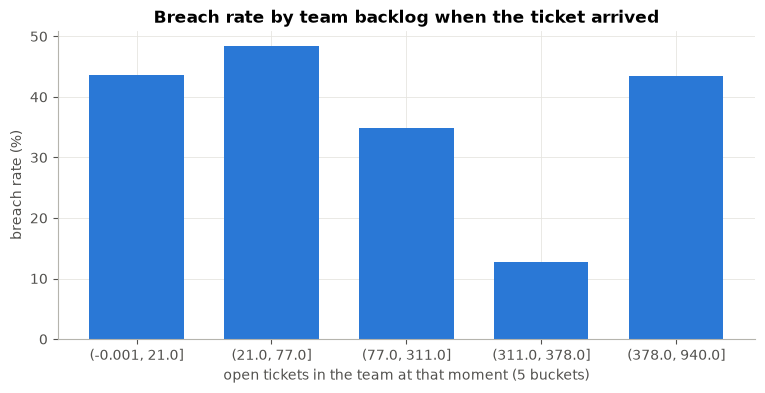

In [7]:
bucket = pd.qcut(t["group_backlog_at_open"], 5, duplicates="drop")
rate = t.groupby(bucket, observed=True)["breached"].mean() * 100
fig, ax = plt.subplots()
ax.bar([str(i) for i in rate.index], rate.values, color=BLUE, width=0.7)
ax.set_title("Breach rate by team backlog when the ticket arrived")
ax.set_xlabel("open tickets in the team at that moment (5 buckets)")
ax.set_ylabel("breach rate (%)")
fig.savefig(FIG / "inc_breach_by_backlog.png", dpi=120, bbox_inches="tight")
plt.show()

**Note:** the data starts on 29 Feb, so for the first days the backlog is under-counted (tickets opened earlier aren't in the file). It's a small edge effect; keep it in mind.

## Step 6: History features: how did similar tickets go in the past?
A team that breached a lot last month will probably breach more this month. We compute, for each ticket, the **past breach rate** of:
its team, its category, its location, and its caller.

⚠ **The leakage trap:** we can only count past tickets whose outcome was **already known** when this ticket opened, i.e. tickets that were **resolved before** this one was opened.
A ticket opened yesterday that is still open doesn't have an outcome yet.

**Smoothing:** a team with only 2 past tickets (both breached) would get a 100% rate, which is too extreme. So we blend each rate with the overall average, like adding 20 "average" tickets:

`smoothed_rate = (breaches + 20 × overall_rate) / (past_tickets + 20)`

With few past tickets you get close to the overall rate; with many you get the team's real rate.

In [8]:
PRIOR = t.loc[t["split"] == "train", "breached"].mean()   # overall breach rate, from training data only
M = 20

def past_mean(df, key, value_col, known_col, query_col, m=M, prior=PRIOR, window=None):
    """For each row: smoothed mean of value_col over rows with the same key whose
    known_col (time the value became known) is before this row's query_col (time).
    If window is given (e.g. 7 days), only rows that became known in that window count."""
    out_mean = np.full(len(df), np.nan)
    out_n = np.zeros(len(df), dtype=int)
    groups = df.groupby(key).groups if key else {"all": df.index}
    for k, idx in groups.items():
        sub = df.loc[idx]
        order = np.argsort(sub[known_col].values)
        known_times = sub[known_col].values[order]
        cum_values = np.concatenate([[0.0], np.cumsum(sub[value_col].values[order])])
        q = sub[query_col].values
        hi = np.searchsorted(known_times, q, side="left")          # known before q
        lo = np.zeros_like(hi) if window is None else np.searchsorted(known_times, q - window, side="left")
        n_known = hi - lo
        total = cum_values[hi] - cum_values[lo]
        pos = df.index.get_indexer(idx)
        out_n[pos] = n_known
        out_mean[pos] = (total + m * prior) / (n_known + m)
    return out_mean, out_n

for key in ["assignment_group", "category", "location", "caller_id"]:
    rate, n = past_mean(t, key, "breached", "_done_at", "opened_at")
    t[f"{key}_past_breach_rate"] = rate
    t[f"_{key}_past_tickets"] = n      # underscore = helper column, NOT a feature (see note below)
    describe(f"{key}_past_breach_rate",
             f"smoothed breach rate of earlier tickets with the same {key} resolved before this one opened (m=20)", "history")

t[["assignment_group", "opened_at", "assignment_group_past_breach_rate", "_assignment_group_past_tickets"]].tail()

,assignment_group,opened_at,assignment_group_past_breach_rate,_assignment_group_past_tickets
24639,Group 70,2016-05-31 20:04:00,0.241484,12395
24640,Group 70,2016-05-31 20:15:00,0.241484,12395
24641,Group 56,2016-05-31 20:43:00,0.390467,103
24642,Group 70,2016-05-31 20:53:00,0.241484,12395
24643,Group 70,2016-05-31 20:55:00,0.241484,12395


⚠ **Why `_past_tickets` is NOT a feature: the "hidden clock" trap.**
"Number of past tickets" only ever goes **up** over time, so it secretly tells the model *what date it is*.
The model then learns "later tickets breach less" (true in this data because of the drift), which looks great in the test but is not a real cause and will break on new data.
We tried it: with these counts the test score was higher, and the top feature was a count. That's a warning sign, not a success. So we keep the counts only as helpers.
Counts over a **fixed window** (like "last 7 days") are fine, because they don't keep growing.

**Recent history (last 7 days).** Because of the drift, "how are things going *this week*" matters more than all-time averages.
Same idea, but only counting tickets resolved in the 7 days before this ticket opened.

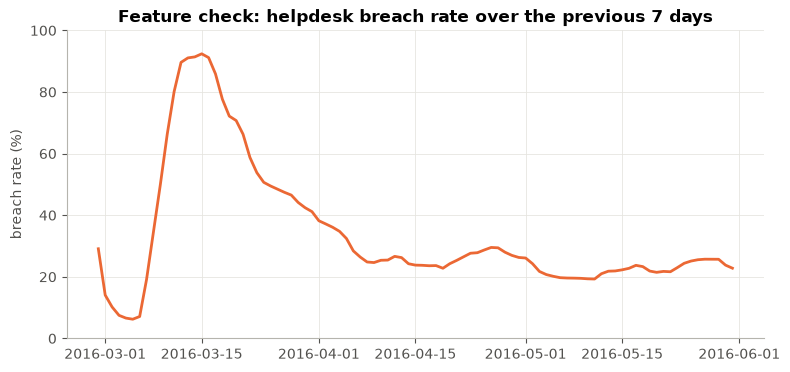

In [9]:
week = np.timedelta64(7, "D")
t["recent_breach_rate_7d"], t["recent_resolved_7d"] = past_mean(t, None, "breached", "_done_at", "opened_at", window=week)
t["group_recent_breach_rate_7d"], _ = past_mean(t, "assignment_group", "breached", "_done_at", "opened_at", window=week)
describe("recent_breach_rate_7d", "smoothed breach rate of ALL tickets resolved in the 7 days before this one opened", "history")
describe("recent_resolved_7d", "number of tickets resolved helpdesk-wide in the 7 days before opening", "history")
describe("group_recent_breach_rate_7d", "same as recent_breach_rate_7d but only for the same assignment_group", "history")

daily = t.set_index("opened_at")["recent_breach_rate_7d"].resample("D").mean() * 100
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color=ORANGE, linewidth=2)
ax.set_title("Feature check: helpdesk breach rate over the previous 7 days")
ax.set_ylabel("breach rate (%)")
ax.set_ylim(0, 100)
plt.show()

Also useful: how long did this category usually take in the past? We use the log of hours (so a few very slow tickets don't dominate).

In [10]:
t["_log_hours"] = np.log1p(t["hours_to_resolve"])
prior_hours = t.loc[t["split"] == "train", "_log_hours"].mean()
valid = t["_log_hours"].notna()
rate, _ = past_mean(t[valid], "category", "_log_hours", "_done_at", "opened_at", prior=prior_hours)
t["category_past_log_hours"] = np.nan
t.loc[valid, "category_past_log_hours"] = rate
# tickets with no resolution time: give them the overall value
t["category_past_log_hours"] = t["category_past_log_hours"].fillna(prior_hours)
describe("category_past_log_hours", "smoothed mean log(1+hours to resolve) of earlier resolved tickets in the same category", "history")

And how many tickets has this caller raised in the last 30 days? (A frequent caller may have a recurring problem.)
We use a fixed 30-day window, not "all time", to avoid the hidden clock.

In [11]:
t["caller_tickets_last_30d"] = 0
for caller, idx in t.groupby("caller_id").groups.items():
    opens = np.sort(t.loc[idx, "opened_at"].values)
    t.loc[idx, "caller_tickets_last_30d"] = count_in_window(opens, t.loc[idx, "opened_at"].values, np.timedelta64(30, "D"))
describe("caller_tickets_last_30d", "tickets the same caller opened in the previous 30 days", "history")
t["caller_tickets_last_30d"].describe().round(1)

count    24644.0
mean         7.2
std         29.0
min          0.0
25%          0.0
50%          2.0
75%          4.0
max        330.0
Name: caller_tickets_last_30d, dtype: float64

## Step 7: Text categories → model-friendly categories
Columns like `category` have 50+ values; `location` and `u_symptom` have hundreds. Rare values (seen only a few times) just add noise.
So we keep the **most common values** and put everything else into `"Other"`.
The "most common" list is decided from the **training tickets only** (so the test period doesn't influence it).

Then we convert them to the pandas `category` type. LightGBM (the model in notebook 07) understands this type directly.

In [12]:
def top_n_or_other(df, col, n):
    top = df.loc[df["split"] == "train", col].value_counts().head(n).index
    return df[col].where(df[col].isin(top), "Other")

cat_plan = {"contact_type": 5, "category": 30, "subcategory": 50, "u_symptom": 50,
            "location": 30, "assignment_group": 30, "opened_by": 30}
for col, n in cat_plan.items():
    t[f"{col}_cat"] = top_n_or_other(t, col, n).astype("category")
    describe(f"{col}_cat", f"{col}, top {n} values from training period, rest = 'Other'", "category")
    print(f"{col:17s} distinct before: {t[col].nunique():>4}   after: {t[f'{col}_cat'].nunique():>3}")

contact_type      distinct before:    2   after:   2
category          distinct before:   46   after:  31
subcategory       distinct before:  218   after:  51
u_symptom         distinct before:  484   after:  51
location          distinct before:  213   after:  31
assignment_group  distinct before:   69   after:  31
opened_by         distinct before:  164   after:  31


## Step 8: Put the final feature table together

In [13]:
feature_cols = [f["feature"] for f in feature_dictionary]
final = t[["number", "opened_at", "split"] + feature_cols + ["breached"]].copy()
print("Feature table:", final.shape)
print("Number of features:", len(feature_cols))
final.head()

Feature table: (24644, 37)
Number of features: 33


,number,opened_at,split,open_hour,open_weekday,is_weekend,is_business_hours,priority_n,impact_n,urgency_n,impact_x_urgency,knowledge,u_priority_confirmation,notify_email,has_cmdb_ci,has_problem_id,group_opened_last_24h,group_opened_last_7d,group_backlog_at_open,all_opened_last_24h,assignment_group_past_breach_rate,category_past_breach_rate,location_past_breach_rate,caller_id_past_breach_rate,recent_breach_rate_7d,recent_resolved_7d,group_recent_breach_rate_7d,category_past_log_hours,caller_tickets_last_30d,contact_type_cat,category_cat,subcategory_cat,u_symptom_cat,location_cat,assignment_group_cat,opened_by_cat,breached
0,INC0000045,2016-02-29 01:16:00,train,1,0,0,0,3.0,2.0,2.0,4.0,1,0,0,0,0,0,0,0,0,0.40137,0.40137,0.40137,0.40137,0.40137,0,0.40137,3.056342,0,Phone,Category 55,Subcategory 170,Other,Location 143,Other,Opened by 8,0
1,INC0000047,2016-02-29 04:40:00,train,4,0,0,0,3.0,2.0,2.0,4.0,1,0,0,0,0,0,0,0,1,0.40137,0.40137,0.40137,0.40137,0.40137,0,0.40137,3.056342,1,Phone,Category 40,Other,Symptom 471,Other,Group 70,Opened by 397,0
2,INC0000057,2016-02-29 06:10:00,train,6,0,0,0,3.0,2.0,2.0,4.0,1,0,0,0,0,1,1,1,2,0.40137,0.40137,0.40137,0.40137,0.40137,0,0.40137,3.056342,0,Phone,Category 20,Subcategory 125,Symptom 471,Location 204,Group 70,Opened by 8,0
3,INC0000060,2016-02-29 06:38:00,train,6,0,0,0,3.0,2.0,2.0,4.0,1,0,0,0,0,0,0,0,3,0.40137,0.40137,0.40137,0.40137,0.40137,0,0.40137,3.056342,0,Phone,Category 9,Other,Other,Location 204,Group 25,Opened by 180,0
4,INC0000062,2016-02-29 06:58:00,train,6,0,0,0,3.0,2.0,2.0,4.0,1,0,0,0,0,2,2,2,4,0.40137,0.40137,0.40137,0.40137,0.40137,0,0.40137,3.056342,0,Phone,Category 53,Subcategory 168,Symptom 232,Location 93,Group 70,Opened by 180,1


## Step 9: Checks before saving
1. One row per ticket.
2. **No leakage columns** slipped in (anything starting with `final_`, or the resolution time).
3. Missing values per feature (LightGBM can handle a few, but we should know about them).

In [14]:
assert final["number"].is_unique
leaky = [c for c in final.columns if c.startswith("final_") or c in ("hours_to_resolve", "resolved_at", "closed_at", "n_events")]
assert not leaky, f"Leaky columns found: {leaky}"
print("No leakage columns ✔")
na = final[feature_cols].isna().sum()
print("Features with missing values:", na[na > 0].to_dict() or "none")

No leakage columns ✔
Features with missing values: none


## Step 10: Save the features and the feature dictionary
The **feature dictionary** lists every feature, how it's computed, and confirms it's known at opening time. It's your proof that the model doesn't cheat.

In [15]:
final.to_parquet(PROCESSED / "incidents_features.parquet", index=False)
fd = pd.DataFrame(feature_dictionary)
fd.to_csv(REPORTS / "incidents_feature_dictionary.csv", index=False)
print("Saved data/processed/incidents_features.parquet and reports/incidents_feature_dictionary.csv")
fd

Saved data/processed/incidents_features.parquet and reports/incidents_feature_dictionary.csv


,feature,how_it_is_computed,group,known_at_ticket_opening
0,open_hour,hour of opened_at (0-23),time,yes
1,open_weekday,day of week of opened_at (0=Mon),time,yes
2,is_weekend,1 if opened on Sat/Sun,time,yes
3,is_business_hours,1 if opened Mon-Fri 08:00-17:59,time,yes
4,priority_n,"priority number, 1=Critical 4=Low",severity,yes
5,impact_n,"impact number, 1=High",severity,yes
6,urgency_n,"urgency number, 1=High",severity,yes
7,impact_x_urgency,impact_n * urgency_n,severity,yes
8,knowledge,1 if knowledge was set on the first event,flags,yes
9,u_priority_confirmation,1 if u_priority_confirmation was set on the fi...,flags,yes


➡ Next: the sales dataset, starting with **04_sales_eda.ipynb**. (Notebook 07 trains a quick model on both feature tables to check everything works.)